In [29]:
import re
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

In [13]:
data_dir = "pan25-generative-ai-detection-task2-train"

train_df = pd.read_json(f"{data_dir}/train.jsonl", lines=True)
dev_df = pd.read_json(f"{data_dir}/dev.jsonl", lines=True)

label_order = [0, 1, 2, 3, 4, 5]

train_df.head()

,text,language,label,source_dataset,model,label_text
0,Have you ever had to wait for something for a ...,English,4,TriBERT,chatgpt,deeply-mixed text; where some parts are writte...
1,"But now, things were not so simple._SEP_The gi...",English,3,RoFT_chatgpt,llm1-llm2,"human-initiated, then machine-continued"
2,"Dear Editor, I am writing to express my opini...",English,4,TriBERT,chatgpt,deeply-mixed text; where some parts are writte...
3,Humans once wielded formidable magical power. ...,English,4,Coauthor,gpt-3,deeply-mixed text; where some parts are writte...
4,"Here is a way that I had to be patient, and we...",English,4,TriBERT,chatgpt,deeply-mixed text; where some parts are writte...


In [14]:
def clean_text(text):
    text = str(text)
    text = text.replace("_SEP_", " ")
    text = text.replace("\n", " ")
    text = text.replace("\r", " ")
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

train_df["text_clean"] = train_df["text"].map(clean_text)
dev_df["text_clean"] = dev_df["text"].map(clean_text)

X_train = train_df["text_clean"]
y_train = train_df["label"].astype(int)

X_test = dev_df["text_clean"]
y_test = dev_df["label"].astype(int)

In [15]:
pipeline = Pipeline(
    steps=[
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=100_000, min_df=5, sublinear_tf=True)),
        ("lr", LogisticRegression(solver="saga", max_iter=500, random_state=1, class_weight="balanced")),
    ]
)

In [16]:
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

c:\git\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


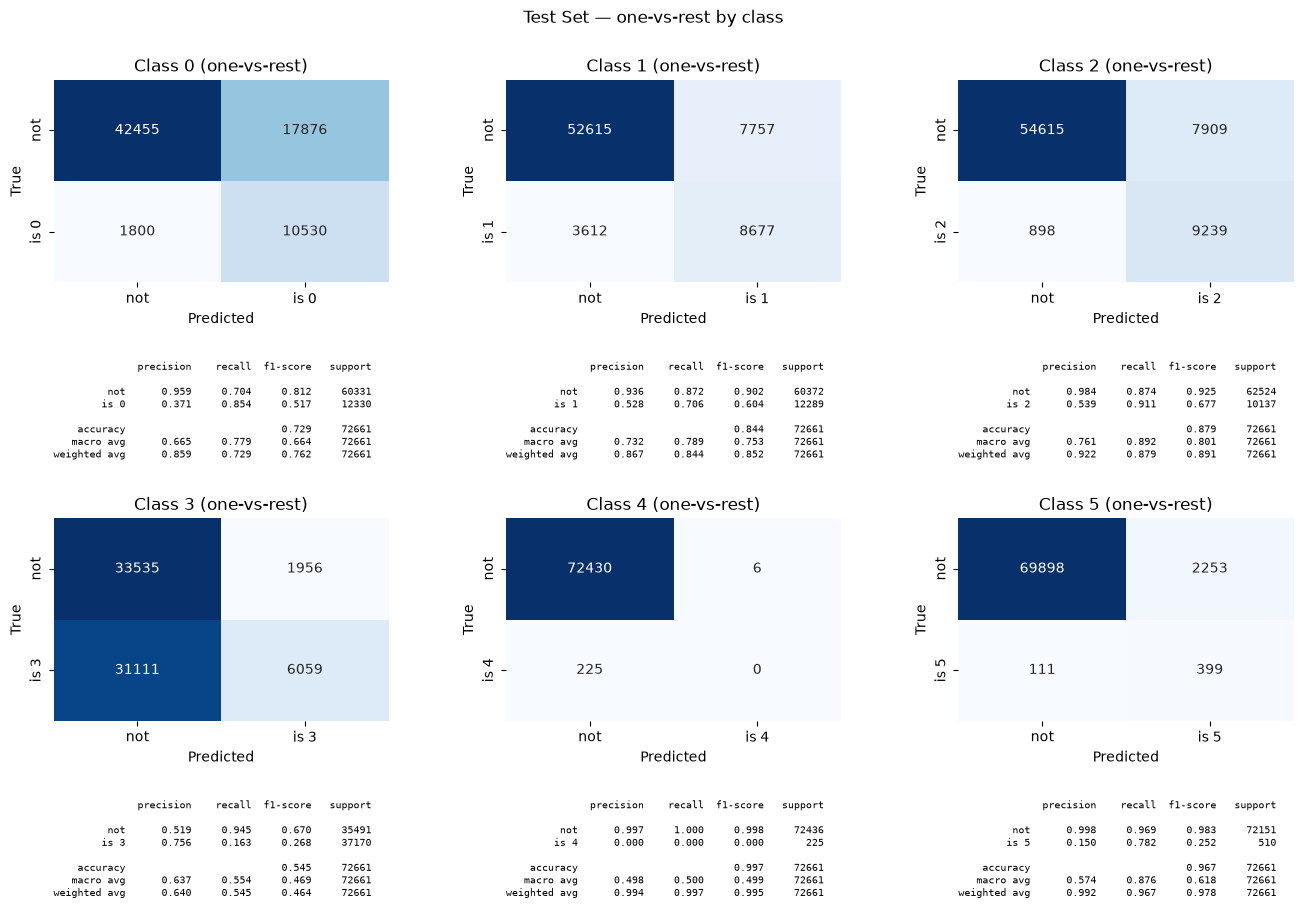

In [31]:
fig = plt.figure(figsize=(16, 10))
outer = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1, 1], hspace=0.12)

for block, labels_in_block in enumerate([label_order[:3], label_order[3:]]):
    inner = gridspec.GridSpecFromSubplotSpec(
        2,
        3,
        subplot_spec=outer[block],
        height_ratios=[2.2, 1.2],
        hspace=0.5,
        wspace=0.35,
    )

    for col, label in enumerate(labels_in_block):
        ax_cm = fig.add_subplot(inner[0, col])
        ax_report = fig.add_subplot(inner[1, col])

        y_true_bin = (y_test == label).astype(int)
        y_pred_bin = (y_pred == label).astype(int)
        cm = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1])

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=["not", f"is {label}"],
            yticklabels=["not", f"is {label}"],
            ax=ax_cm,
        )
        ax_cm.set_xlabel("Predicted")
        ax_cm.set_ylabel("True")
        ax_cm.set_title(f"Class {label} (one-vs-rest)")

        report_str = classification_report(
            y_true_bin,
            y_pred_bin,
            labels=[0, 1],
            target_names=["not", f"is {label}"],
            digits=3,
            zero_division=0,
        )
        ax_report.axis("off")
        ax_report.text(
            0.0,
            1.0,
            report_str,
            transform=ax_report.transAxes,
            va="top",
            ha="left",
            fontsize=7.5,
            family="monospace",
        )

plt.suptitle("Test Set — one-vs-rest by class", y=1.01)
fig.subplots_adjust(top=0.94)
plt.show()

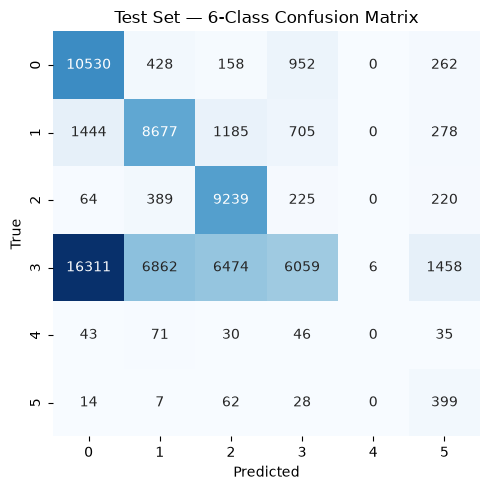

              precision    recall  f1-score   support

           0      0.371     0.854     0.517     12330
           1      0.528     0.706     0.604     12289
           2      0.539     0.911     0.677     10137
           3      0.756     0.163     0.268     37170
           4      0.000     0.000     0.000       225
           5      0.150     0.782     0.252       510

    accuracy                          0.480     72661
   macro avg      0.391     0.569     0.386     72661
weighted avg      0.615     0.480     0.423     72661



In [24]:
cm_full = confusion_matrix(y_test, y_pred, labels=label_order)

fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(
    cm_full,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=label_order,
    yticklabels=label_order,
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Test Set — 6-Class Confusion Matrix")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_test,
        y_pred,
        labels=label_order,
        digits=3,
        zero_division=0,
    )
)